In [1]:
import torch
import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio, display
from transformers import WhisperProcessor, WhisperForConditionalGeneration

# Set the audio filename - update this to your actual filename
audio_file = "Kokeilu_1.m4a"

# pip install transformers
# pip install librosa
# pip install ipywidgets
# pip install PySoundFile
# conda install -c conda-forge libsndfile
# pip install sentencepiece
# pip install sacremoses

/opt/anaconda3/envs/keras/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1104 14:46:34.009000 1619 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


In [2]:
# Load audio file
y, sr = librosa.load(audio_file, sr=16000)

# Display audio for playback
print("Play the audio:")
display(Audio(y, rate=sr))

# Print audio statistics
duration = librosa.get_duration(y=y, sr=sr)
print(f"\nAudio Statistics:")
print(f"Duration: {duration:.2f} seconds")
print(f"Sample rate: {sr} Hz")

/var/folders/wh/9dhw52gj7c18zhl8y4z0dy9w0000gn/T/ipykernel_1619/1997904896.py:2: UserWarning: PySoundFile failed. Trying audioread instead.
  y, sr = librosa.load(audio_file, sr=16000)
/opt/anaconda3/envs/keras/lib/python3.11/site-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


Play the audio:



Audio Statistics:
Duration: 10.30 seconds
Sample rate: 16000 Hz


In [7]:
import sys
import librosa
from pathlib import Path

print("Python:", sys.executable)
print("Librosa:", librosa.__version__)
print("Äänitiedosto:", audio_file)
print("Tiedoston polku:", Path(audio_file).resolve())

Python: /opt/anaconda3/envs/keras/bin/python3.11
Librosa: 0.11.0
Äänitiedosto: Kokeilu_1.m4a
Tiedoston polku: /Users/eliasrinne/Documents/neuroverkkokurssi/Kokeilu_1.m4a


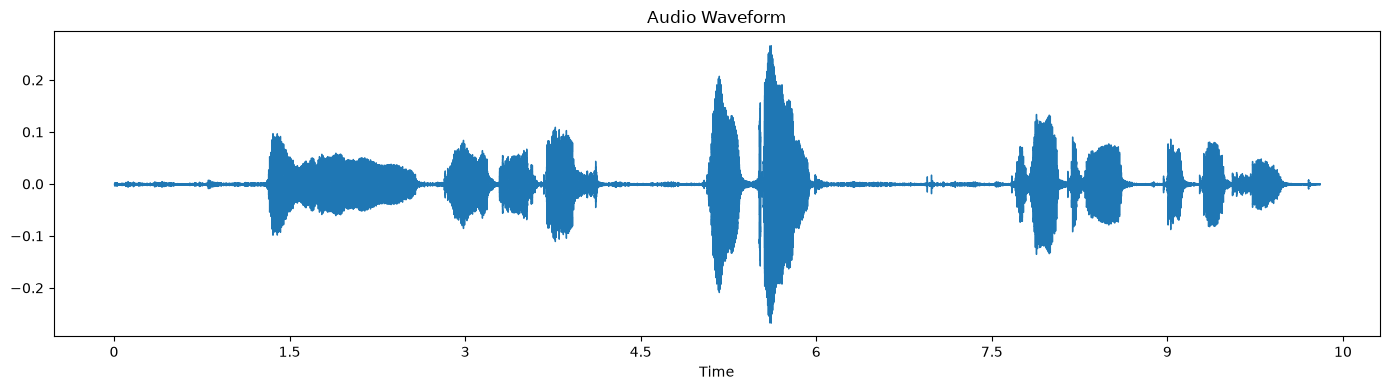

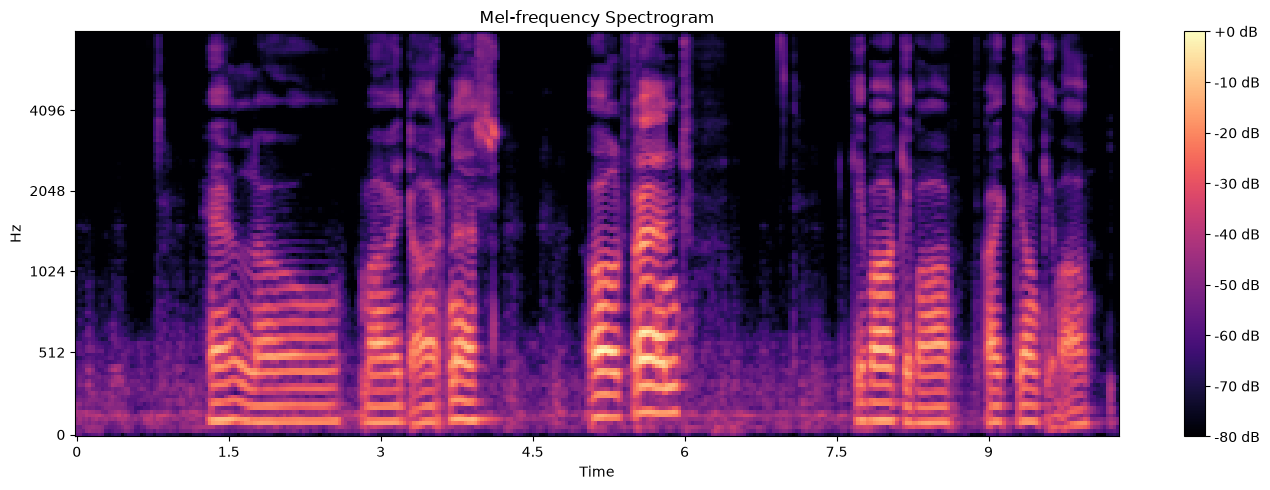

In [3]:
# Plot waveform
plt.figure(figsize=(14, 4))
librosa.display.waveshow(y, sr=sr)
plt.title('Audio Waveform')
plt.tight_layout()
plt.show()

# Create mel spectrogram
plt.figure(figsize=(14, 5))
S = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128)
S_dB = librosa.power_to_db(S, ref=np.max)
librosa.display.specshow(S_dB, y_axis='mel', x_axis='time', sr=sr)
plt.colorbar(format='%+2.0f dB')
plt.title('Mel-frequency Spectrogram')
plt.tight_layout()
plt.show()

In [4]:
# Initialize the model
model_size = "large"  # Options: tiny, base, small, medium, large
device = "cuda" if torch.cuda.is_available() else "cpu"
device = "mps" if torch.mps.is_available() else "cpu"
print(f"Using device: {device}")

# Load model and processor
print(f"Loading Whisper {model_size} model...")
model_name = f"openai/whisper-{model_size}"
processor = WhisperProcessor.from_pretrained(model_name)
model = WhisperForConditionalGeneration.from_pretrained(model_name).to(device)

# Set the language to Finnish
forced_decoder_ids = processor.get_decoder_prompt_ids(language="fi", task="transcribe")

# Process with WhisperProcessor
print("Processing audio...")
input_features = processor(
    y, 
    sampling_rate=sr, 
    return_tensors="pt"
).input_features.to(device)

# Generate the transcription
print("Generating transcription...")
with torch.no_grad():
    generated_ids = model.generate(
        input_features,
        language="fi",
        task="transcribe"
    )

# Decode the generated IDs
transcription = processor.batch_decode(
    generated_ids, 
    skip_special_tokens=True
)[0]

print("\nFINNISH TRANSCRIPTION:")
print("="*50)
print(transcription)

Using device: mps
Loading Whisper large model...


Loading weights: 100%|██████████████████| 1259/1259 [00:00<00:00, 10473.86it/s]


Processing audio...
Generating transcription...


[transformers] Passing `generation_config` together with generation-related arguments=({'suppress_tokens', 'begin_suppress_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer WhisperTokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.



FINNISH TRANSCRIPTION:
 Hello my darkness old friend. Kiva kiva, kaikki on kivaa.


In [5]:
# Set the task to translate
forced_decoder_ids_translate = processor.get_decoder_prompt_ids(language="fi", task="translate")

# Generate the translation
print("Generating English translation...")
with torch.no_grad():
    generated_ids = model.generate(
        input_features,
        language="en",
        task="transcribe"
    )

# Decode the generated IDs
translation = processor.batch_decode(
    generated_ids, 
    skip_special_tokens=True
)[0]

print("\nENGLISH TRANSLATION:")
print("="*50)
print(translation)

Generating English translation...

ENGLISH TRANSLATION:
 Hello, my darkness, old friend. Kiva, kiva, kaikki on kiva.


In [6]:
from transformers import MarianMTModel, MarianTokenizer

# Load a dedicated Finnish to English translation model
model_name = "Helsinki-NLP/opus-mt-fi-en"
translation_tokenizer = MarianTokenizer.from_pretrained(model_name)
translation_model = MarianMTModel.from_pretrained(model_name)

# Translate the Finnish transcription
inputs = translation_tokenizer(transcription, return_tensors="pt")
translated = translation_model.generate(**inputs)
better_translation = translation_tokenizer.decode(translated[0], skip_special_tokens=True)

print("BETTER ENGLISH TRANSLATION:")
print("="*50)
print(better_translation)

ImportError: 
MarianTokenizer requires the SentencePiece library but it was not found in your environment. Check out the instructions on the
installation page of its repo: https://github.com/google/sentencepiece#installation and follow the ones
that match your environment. Please note that you may need to restart your runtime after installation.
